# Chapter 35 - A First Model, and Why It Failed

Chapter 35 is about the most dangerous model Sedge Shoes builds: the one with clean diagnostics and a Paid Search return nobody should believe.
This notebook follows the chapter step by step on the companion's Sedge panel, with the case-study model in `mmm_book.case_model`.
That is the model the chapter describes: regional, with a separately estimated level for each of the 18 regions and regional media effects partially pooled around the national one, a wide independent prior on each product launch, geometric adstock and Hill saturation with both transforms estimated, priors placed directly on each channel's return on ad spend, and the agreed control set.

The order is the chapter's.
A baseline model comes first and finds a data problem.
The priors are designed, then checked by sampling from them.
Model 1 fits cleanly and gets Paid Search badly wrong.
Splitting Search into brand and generic fixes it, and the Meta and YouTube split is reported as uncertain.

Each fit uses four chains of 1,000 tuning and 2,000 posterior draws at a target acceptance rate of 0.97 and takes a few minutes.
`fit_case_model` caches each fit on disk, so the later notebooks can reuse it.

In [1]:
import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
from scipy import stats

from mmm_book import RANDOM_SEED
from mmm_book.adstock import geometric_adstock
from mmm_book.case_model import (
    FIRST_PRIORS,
    PRIORS,
    build_case_model,
    contribution_draws,
    fit_case_model,
    fit_summary,
    posterior_mu,
    prepare_case_data,
    roas_table,
)
from mmm_book.plotting import mmm_style
from mmm_book.sedge import (
    CHANNELS,
    GROUND_TRUTH,
    RETAILER_ONBOARDING,
    correct_distribution,
    generate_sedge,
)

mmm_style()
pd.set_option("display.width", 120)
df = generate_sedge(seed=RANDOM_SEED)

## A baseline model first

Before any media variable is added, the chapter fits a baseline: regional intercepts, a trend, annual Fourier seasonality, and the controls.
A quick least-squares fit of log revenue is enough for this job.
It should miss the campaign periods, because media are not in it yet.
Most campaigns hit every region in the same week, so comparing each region's residual with the average residual across regions that week takes them out, and what is left should look like noise.
What it should not do is leave a long run of same-signed errors in one region.

In [2]:
def baseline_residuals(panel):
    week = panel["week"].to_numpy()
    woy = week % 52
    X = [
        pd.get_dummies(panel["region"], dtype=float).to_numpy(),
        ((week - week.mean()) / week.std())[:, None],
    ]
    for k in (1, 2):
        X.append(
            np.column_stack([np.sin(2 * np.pi * k * woy / 52), np.cos(2 * np.pi * k * woy / 52)])
        )
    controls = np.column_stack(
        [
            np.log(panel["price"]),
            panel["promo_depth"],
            np.log(panel["distribution"]),
            np.log(panel["stock"]),
            panel["temperature"],
            panel["rainfall"],
            panel["launch"],
            np.log(panel["category_search"]),
        ]
    )
    X = np.column_stack(X + [controls])
    y = np.log(panel["revenue"].to_numpy())
    coef, *_ = np.linalg.lstsq(X, y, rcond=None)
    resid = panel.assign(resid=y - X @ coef).pivot(index="week", columns="region", values="resid")
    # relative to the other regions in the same week, in per cent
    return 100 * resid.sub(resid.mean(axis=1), axis=0)


resid = baseline_residuals(df)
run = resid.rolling(12).mean()
worst = run.max().sort_values(ascending=False)
print("largest 12-week average residual, relative to the other regions (per cent)")
print(worst.head(4).round(1))

largest 12-week average residual, relative to the other regions (per cent)
region
region_11    9.8
region_12    7.4
region_17    6.6
region_13    6.5
dtype: float64


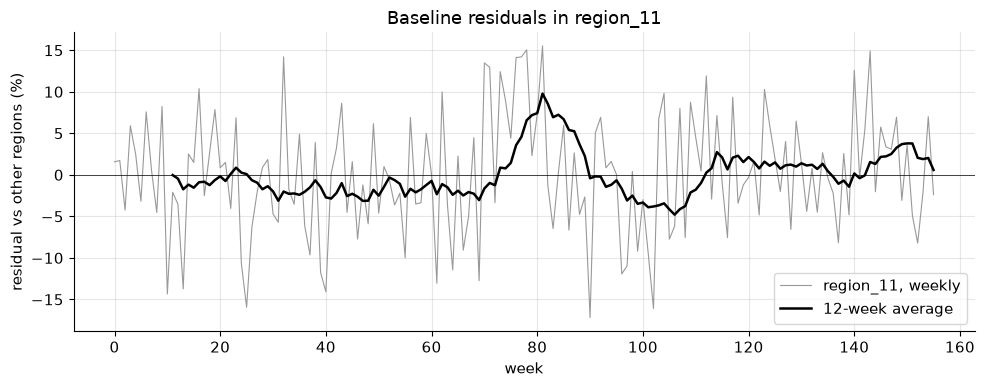

In [3]:
region = RETAILER_ONBOARDING["region"]
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(resid.index, resid[region], color="0.6", lw=0.8, label=f"{region}, weekly")
ax.plot(run.index, run[region], color="k", lw=1.8, label="12-week average")
ax.axhline(0, color="k", lw=0.5)
ax.set_xlabel("week")
ax.set_ylabel("residual vs other regions (%)")
ax.set_title(f"Baseline residuals in {region}")
ax.legend()
fig.tight_layout()

One region stands out, with a run of positive residuals that starts in week 70 and lasts twelve weeks.
In the chapter the investigation finds a commercial cause: a new retail partner went live, but the distribution data were updated three months late.
The generator records exactly that (`RETAILER_ONBOARDING`), and `correct_distribution` applies the fix the commercial team's onboarding date supports.

In [4]:
fixed = correct_distribution(df)
resid_fixed = baseline_residuals(fixed)
w0, lag = RETAILER_ONBOARDING["week"], RETAILER_ONBOARDING["lag_weeks"]
window = slice(w0, w0 + lag - 1)
print(
    f"{region}, weeks {w0} to {w0 + lag - 1}: mean residual "
    f"{resid.loc[window, region].mean():+.1f}% before the fix, "
    f"{resid_fixed.loc[window, region].mean():+.1f}% after"
)

ooh = df.pivot(index="week", columns="region", values="ooh_spend")
print(
    f"OOH spend in {region}: {ooh.loc[window, region].mean():,.0f} a week in those weeks, "
    f"{ooh[region].mean():,.0f} on average"
)

region_11, weeks 70 to 81: mean residual +9.8% before the fix, +2.7% after
OOH spend in region_11: 2,627 a week in those weeks, 1,181 on average


The fix removes most of the run; what is left is the OOH push itself, which a baseline without media cannot explain.
It also explains the chapter's remark that the correction later reduces apparent OOH contribution: the new retailer opened with an OOH push, so before the fix OOH was the only variable in the model that rose in the right region in the right weeks.
Every fit from here on uses the corrected panel.
No statistical technique would have found the commercial explanation on its own; the residual only said where to look.

## Prior design

The chapter's priors are statements about return on ad spend, so the model puts its priors on ROAS directly.
Each prior is a LogNormal with the median and log-scale spread below.
Television gets an informative but widened prior near 2.2 times, from two historical geo tests.
Meta gets a moderately informative prior near 1.8 times, kept broad because the earlier test covered prospecting only.
YouTube gets a weak positive prior.
Search gets a prior that allows a strong return but excludes the values platform attribution produces.
OOH gets a broad positive prior.
Adstock retention gets Beta priors, and the half-saturation point a LogNormal prior as a multiple of each region's average weekly activity.

In [5]:
prior_table = pd.DataFrame(
    {
        "ROAS median": {ch: FIRST_PRIORS.roas[ch][0] for ch in CHANNELS},
        "ROAS log-sd": {ch: FIRST_PRIORS.roas[ch][1] for ch in CHANNELS},
        "adstock Beta(a, b)": {ch: FIRST_PRIORS.adstock[ch] for ch in CHANNELS},
        "half-saturation median": {ch: FIRST_PRIORS.saturation[ch][0] for ch in CHANNELS},
    }
)
prior_table

,ROAS median,ROAS log-sd,"adstock Beta(a, b)",half-saturation median
tv,2.2,0.35,"(3.0, 3.0)",3.0
search,2.5,0.50,"(2.0, 2.0)",1.0
meta,1.8,0.45,"(2.0, 3.0)",1.5
youtube,1.5,0.80,"(2.0, 3.0)",3.0
ooh,1.2,1.50,"(3.0, 3.0)",3.0


## Sampling from the priors

Before fitting, the team samples from the priors and reads the draws in business units.
Annual contribution is ROAS times annual spend, and a Search adstock retention converts to a half-life in weeks.

In [6]:
data = prepare_case_data(fixed, "model1")
annual_spend = {ch: data.annual_spend(ch) for ch in CHANNELS}


def prior_draws(priors):
    with build_case_model(data, priors, store_mu=False):
        prior = pm.sample_prior_predictive(
            draws=4000,
            var_names=[f"roas_{ch}" for ch in CHANNELS] + ["alpha_search"],
            random_seed=RANDOM_SEED,
        ).prior
    return {name: prior[name].to_numpy().ravel() for name in prior.data_vars}


def report(draws, label):
    ooh_m = draws["roas_ooh"] * annual_spend["ooh"] / 1e6
    half_life = np.log(0.5) / np.log(draws["alpha_search"])
    print(label)
    print(
        f"  OOH annual contribution: median {np.median(ooh_m):.1f}m, 99th percentile "
        f"{np.quantile(ooh_m, 0.99):.1f}m, "
        f"share of draws above 20m: {(ooh_m > 20).mean():.1%}"
    )
    print(
        f"  Search adstock half-life: share of draws beyond 8 weeks: {(half_life > 8).mean():.1%}"
    )


first = prior_draws(FIRST_PRIORS)
report(first, "first priors")

# The same shares, exactly, from the prior distributions (the figures the book prints).

median, sd = FIRST_PRIORS.roas["ooh"]
a, b = FIRST_PRIORS.adstock["search"]
print(
    f"exact: OOH above 20m {stats.lognorm(sd, scale=median).sf(20e6 / annual_spend['ooh']):.1%}, "
    f"Search half-life beyond 8 weeks {stats.beta(a, b).sf(0.5 ** (1 / 8)):.1%}"
)

Sampling: [alpha_search, roas_meta, roas_ooh, roas_search, roas_tv, roas_youtube]


first priors
  OOH annual contribution: median 1.1m, 99th percentile 36.5m, share of draws above 20m: 2.9%
  Search adstock half-life: share of draws beyond 8 weeks: 2.2%
exact: OOH above 20m 2.6%, Search half-life beyond 8 weeks 2.0%


The first OOH prior lets OOH contribute more than £20 million a year in a non-trivial share of draws.
Against £900,000 of spend and Sedge's £48 million of revenue that would describe an extreme business, so the prior is tightened until high returns stay possible but fantastical ones get little probability.
Search's first adstock prior allows half-lives beyond eight weeks, which the team considers implausible for a short-run revenue mechanism, so most of the probability moves to faster decay.
Television's adstock prior stays broad.

In [7]:
final = prior_draws(PRIORS)
report(final, "final priors")
print()
print(
    pd.DataFrame(
        {
            "first OOH prior": [FIRST_PRIORS.roas["ooh"]],
            "final OOH prior": [PRIORS.roas["ooh"]],
            "first Search adstock": [FIRST_PRIORS.adstock["search"]],
            "final Search adstock": [PRIORS.adstock["search"]],
        }
    ).T.rename(columns={0: "(median, log-sd) or Beta(a, b)"})
)

Sampling: [alpha_search, roas_meta, roas_ooh, roas_search, roas_tv, roas_youtube]


final priors
  OOH annual contribution: median 1.1m, 99th percentile 4.4m, share of draws above 20m: 0.0%
  Search adstock half-life: share of draws beyond 8 weeks: 0.0%

                     (median, log-sd) or Beta(a, b)
first OOH prior                          (1.2, 1.5)
final OOH prior                          (1.2, 0.6)
first Search adstock                     (2.0, 2.0)
final Search adstock                     (2.0, 6.0)


## Model 1

The first full model uses all five channels as the media treatments, with total Paid Search spend as the Search treatment, geometric adstock and Hill saturation, partial pooling across regions, two annual Fourier pairs and the agreed control set.

In [8]:
idata1 = fit_case_model(fixed, "model1")
data1 = prepare_case_data(fixed, "model1")

# Diagnostics on every free parameter, not only the ones in the table.
free = [
    v
    for v in idata1.posterior.data_vars
    if not v.startswith(("beta_", "channel_contribution")) and v not in ("roas", "level")
]
summary = az.summary(idata1, var_names=free, kind="diagnostics")
print(f"divergent transitions: {int(idata1.sample_stats['diverging'].sum())}")
print(
    f"largest r_hat: {summary['r_hat'].max():.3f}, smallest bulk ESS: "
    f"{summary['ess_bulk'].min():.0f}, smallest tail ESS: {summary['ess_tail'].min():.0f}"
)

mu1 = posterior_mu(idata1, data1)
fit1 = fit_summary(mu1, data1)
print(f"in-sample R squared: {fit1['r2']:.3f}, weighted MAPE: {fit1['wmape']:.1%}")

divergent transitions: 0
largest r_hat: 1.003, smallest bulk ESS: 921, smallest tail ESS: 1525
in-sample R squared: 0.928, weighted MAPE: 5.1%


Sampling is clean and the fit is strong, which is the chapter's point: nothing in the sampler objects.
Now the channel results, the table Chapter 35 prints, with the truth the generator built in beside them (the chapter does not show the truth; Appendix F does).

In [9]:
t1 = roas_table(idata1, data1)
t1["truth"] = pd.Series(GROUND_TRUTH)
t1.round(2)

,roas_mean,roas_lo,roas_hi,annual_contribution_m,truth
channel,,,,,
tv,2.21,2.05,2.38,3.10,2.40
search,4.68,3.91,5.52,6.55,2.70
meta,1.28,0.76,1.95,1.93,1.75
youtube,1.42,0.65,2.33,1.14,2.00
ooh,1.59,1.12,2.16,1.43,1.50


Search looks suspicious at once.
A return of around five times is not impossible, but it is far above what the pause test and management expect once branded demand capture is considered, and the truth here is 2.7.
At 4.7 times Search would account for about £6.6 million a year, more than Television and YouTube together.
Predictive fit and sampling diagnostics are both good, and the model is still wrong in the place that matters most for the budget.

## Investigating Search

The team decomposes Search.
Brand search spend is driven by branded query volume, which responds to underlying demand and to upper-funnel media, so it is partly a demand-capture mechanism.
Generic search has more independent variation.

In [10]:
brand_share = fixed["search_brand_spend"].sum() / fixed["search_spend"].sum()
print(f"brand share of Paid Search spend: {brand_share:.0%}")

nat = fixed.groupby("week").sum(numeric_only=True)
week = fixed["week"].to_numpy()
X = np.column_stack(
    [pd.get_dummies(fixed["region"], dtype=float).to_numpy(), (week - week.mean()) / week.std()]
    + [f(2 * np.pi * k * (week % 52) / 52) for k in (1, 2) for f in (np.sin, np.cos)]
    + [np.log(fixed[c]) for c in ("price", "distribution", "stock", "category_search")]
    + [fixed[c] for c in ("promo_depth", "temperature", "rainfall", "launch")]
)
y = np.log(fixed["revenue"].to_numpy())
coef, *_ = np.linalg.lstsq(X, y, rcond=None)
base_resid = fixed.assign(r=y - X @ coef).groupby("week")["r"].mean()
for col in ("search_brand_spend", "search_generic_impr"):
    print(
        f"{col:<22} correlation with the baseline model's national residual: "
        f"{np.corrcoef(nat[col], base_resid)[0, 1]:.2f}"
    )

brand share of Paid Search spend: 40%


search_brand_spend     correlation with the baseline model's national residual: 0.60
search_generic_impr    correlation with the baseline model's national residual: -0.03


Brand spend tracks the demand the baseline cannot explain much more closely than generic search does, which is the signature of a channel that follows sales rather than causing them.

The chapter changes three things.
Generic Search impressions replace total Search spend as the Search treatment.
Brand search spend leaves the media set.
And, as a sensitivity check, branded query volume is regressed on Television, Meta and YouTube alongside the controls.
The check comes first: a regression of log branded volume on the controls and the adstocked upper-funnel media.
It credits no revenue to any channel; it asks only whether the three channels raise branded search.

In [11]:
def adstocked(col, alpha=0.5):
    wide = fixed.pivot(index="region", columns="week", values=col)
    return np.concatenate([geometric_adstock(row, alpha) for row in wide.to_numpy()])


wide_order = fixed.sort_values(["region", "week"])
week = wide_order["week"].to_numpy()
woy = week % 52
X = np.column_stack(
    [pd.get_dummies(wide_order["region"], dtype=float).to_numpy()]
    + [np.sin(2 * np.pi * k * woy / 52) for k in (1, 2)]
    + [np.cos(2 * np.pi * k * woy / 52) for k in (1, 2)]
    + [np.log(wide_order[c]) for c in ("price", "distribution", "stock", "category_search")]
    + [wide_order[c] for c in ("promo_depth", "launch")]
    + [np.log1p(adstocked(c) / fixed[c].mean()) for c in ("tv_grps", "meta_spend", "youtube_spend")]
)
y = np.log(wide_order["brand_search_volume"].to_numpy())
coef, *_ = np.linalg.lstsq(X, y, rcond=None)
for name, b in zip(["Television", "Meta", "YouTube"], coef[-3:], strict=True):
    print(f"{name:<11} effect on log branded search volume: {b:+.2f}")

Television  effect on log branded search volume: +0.40
Meta        effect on log branded search volume: +0.18
YouTube     effect on log branded search volume: +0.71


All three upper-funnel channels raise branded search volume, which confirms that revenue arriving through a branded click was created upstream rather than by the click; a model that credited the click would credit the wrong channel.
Now Model 2, with generic impressions as the Search treatment and Search's return still quoted on total Search spend:

In [12]:
idata2 = fit_case_model(fixed, "model2")
data2 = prepare_case_data(fixed, "model2")
print(f"divergent transitions: {int(idata2.sample_stats['diverging'].sum())}")
mu2 = posterior_mu(idata2, data2)
fit2 = fit_summary(mu2, data2)
print(f"in-sample R squared: {fit2['r2']:.3f} (Model 1: {fit1['r2']:.3f})")

t2 = roas_table(idata2, data2)
compare = pd.DataFrame(
    {
        "Model 1": t1["roas_mean"],
        "Model 2": t2["roas_mean"],
        "Model 2 5%": t2["roas_lo"],
        "Model 2 95%": t2["roas_hi"],
        "truth": pd.Series(GROUND_TRUTH),
    }
)
compare.round(2)

divergent transitions: 0


in-sample R squared: 0.926 (Model 1: 0.928)


,Model 1,Model 2,Model 2 5%,Model 2 95%,truth
tv,2.21,2.57,2.41,2.74,2.40
search,4.68,2.23,1.73,2.77,2.70
meta,1.28,1.52,0.90,2.29,1.75
youtube,1.42,2.34,1.36,3.45,2.00
ooh,1.59,1.65,1.14,2.28,1.50


Search falls by half, to 2.2 with a 90 per cent interval (1.7 to 2.8) that includes the true 2.7, and fit barely changes.
The first estimate was not rejected because the model predicted badly.
It was rejected because causal reasoning and outside evidence offered a better explanation of the same sales history.
Part of that outside evidence is already in the data: generic search was switched off in six regions for eight weeks in summer 2022 (`SEARCH_PAUSE`), and those weeks are what pin down Search's level.

## Investigating Meta and YouTube

The next problem is separating Meta from YouTube.

Meta:     mean 2.28m, 90% interval 1.35m to 3.44m
YouTube:  mean 1.87m, 90% interval 1.09m to 2.76m
together: mean 4.15m, 90% interval 3.26m to 5.25m
posterior correlation between the two contributions: -0.45


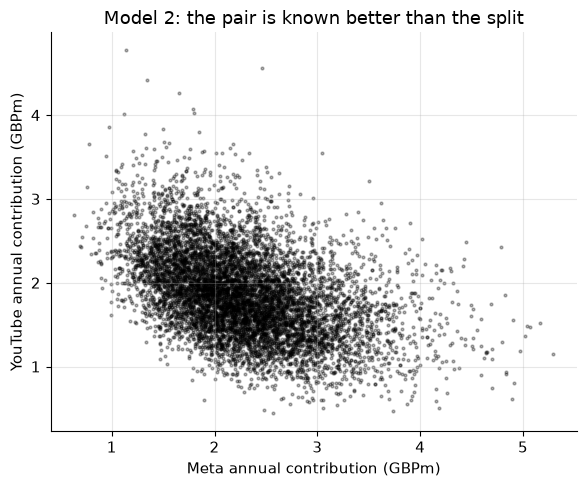

In [13]:
contrib = contribution_draws(idata2, data2)
meta_m, yt_m = contrib["meta"] / 1e6, contrib["youtube"] / 1e6
pair = meta_m + yt_m
print(
    f"Meta:     mean {meta_m.mean():.2f}m, 90% interval {np.quantile(meta_m, 0.05):.2f}m to "
    f"{np.quantile(meta_m, 0.95):.2f}m"
)
print(
    f"YouTube:  mean {yt_m.mean():.2f}m, 90% interval {np.quantile(yt_m, 0.05):.2f}m to "
    f"{np.quantile(yt_m, 0.95):.2f}m"
)
print(
    f"together: mean {pair.mean():.2f}m, 90% interval {np.quantile(pair, 0.05):.2f}m to "
    f"{np.quantile(pair, 0.95):.2f}m"
)
print(f"posterior correlation between the two contributions: {np.corrcoef(meta_m, yt_m)[0, 1]:.2f}")

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(meta_m, yt_m, s=4, alpha=0.3, color="k")
ax.set_xlabel("Meta annual contribution (GBPm)")
ax.set_ylabel("YouTube annual contribution (GBPm)")
ax.set_title("Model 2: the pair is known better than the split")
fig.tight_layout()

The draws slope downwards: when the model gives Meta more, it gives YouTube less.
The data know that the pair matters and are much less sure which channel deserves which part, because the two are planned from one budget.
That is an identification problem, not a sampler problem, and lab 23 (synthetic recovery) and exercise 3 show the same thing under a known truth.
The chapter's remedy is new information, a Meta geo holdout that varies Meta while YouTube stays stable, which is where notebook 36 picks up.
The company could have hidden the uncertainty with stronger priors, and chooses not to.

## Takeaway

A model can pass every diagnostic, fit well and still be wrong where the decision lives.
The baseline caught a data problem that only the business could explain.
The prior predictive check caught priors that described an impossible business.
Causal reasoning about how brand search works caught the inflated Search return.
And the answer on Meta and YouTube is a well-measured total with an uncertain split, until an experiment says more.